In [1]:
import duckdb
con = duckdb.connect()
imputed_path = "/home/iai-labor/traffic_project/traffic_hourly_imputed_parts/*.parquet"
sensor_map_table = con.execute(f"""
SELECT
    SENSOR_ID,
    ANY_VALUE(ELEMENT_TYPE) AS ELEMENT_TYPE,
    ANY_VALUE(LONGITUDE) AS LONGITUDE,
    ANY_VALUE(LATITUDE) AS LATITUDE,
    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.99) AS p99_traffic
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID IS NOT NULL
  AND LONGITUDE IS NOT NULL
  AND LATITUDE IS NOT NULL
GROUP BY SENSOR_ID
ORDER BY SENSOR_ID
""").df()

sensor_map_table.head()

,SENSOR_ID,ELEMENT_TYPE,LONGITUDE,LATITUDE,rows,avg_traffic,median_traffic,max_traffic,p99_traffic
0,1001,C30,-3.740786,40.409729,29928,1586.768286,1551.0,5172.0,4560.00
1,1002,C30,-3.743760,40.408030,29928,1398.052583,1320.0,5250.0,4479.36
2,1003,C30,-3.746834,40.406824,29928,1901.674687,2073.0,6018.0,5460.00
3,1006,C30,-3.736324,40.411894,29928,1425.779141,1200.0,5433.0,4494.18
4,1009,C30,-3.724909,40.416234,29798,1482.950567,1320.0,5298.0,4414.80


In [2]:
sensor_map_table.to_csv(
    "/home/iai-labor/traffic_project/sensor_map_table.csv",
    index=False
)

sensor_map_table.shape

(4845, 9)

In [3]:
con.execute(f"""
SELECT
    COUNT(DISTINCT SENSOR_ID) AS sensors_total,

    COUNT(DISTINCT CASE
        WHEN LONGITUDE IS NOT NULL
         AND LATITUDE IS NOT NULL
        THEN SENSOR_ID
    END) AS sensors_with_coords,

    COUNT(DISTINCT CASE
        WHEN LONGITUDE IS NULL
          OR LATITUDE IS NULL
        THEN SENSOR_ID
    END) AS sensors_without_coords

FROM read_parquet('{imputed_path}')
""").df()

,sensors_total,sensors_with_coords,sensors_without_coords
0,4890,4845,45


In [4]:
missing_coords = con.execute(f"""
SELECT DISTINCT
    SENSOR_ID,
    LONGITUDE,
    LATITUDE
FROM read_parquet('{imputed_path}')
WHERE LONGITUDE IS NULL
   OR LATITUDE IS NULL
ORDER BY SENSOR_ID
""").df()

missing_coords

,SENSOR_ID,LONGITUDE,LATITUDE
0,3618,NaN,NaN
1,3662,NaN,NaN
2,3731,NaN,NaN
3,3791,NaN,NaN
4,3904,NaN,NaN
5,4096,NaN,NaN
6,4152,NaN,NaN
7,4240,NaN,NaN
8,4303,NaN,NaN
9,4757,NaN,NaN


In [6]:
import geopandas as gpd
from shapely.geometry import Point

sensors_gdf = gpd.GeoDataFrame(
    sensor_map_table,
    geometry=gpd.points_from_xy(
        sensor_map_table["LONGITUDE"],
        sensor_map_table["LATITUDE"]
    ),
    crs="EPSG:4326"
)

sensors_gdf.shape

(4845, 10)

In [7]:
con.execute(f"""
DESCRIBE
SELECT *
FROM read_parquet('{imputed_path}')
LIMIT 1
""").df()

,column_name,column_type,null,key,default,extra
0,DATETIME,TIMESTAMP,YES,None,None,None
1,SENSOR_ID,BIGINT,YES,None,None,None
2,ELEMENT_TYPE,VARCHAR,YES,None,None,None
3,TRAFFIC_INTENSITY,DOUBLE,YES,None,None,None
4,OCCUPANCY,DOUBLE,YES,None,None,None
5,LOAD,DOUBLE,YES,None,None,None
6,AVERAGE_SPEED,DOUBLE,YES,None,None,None
7,ERROR_FLAG,VARCHAR,YES,None,None,None
8,INTEGRATION_PERIOD,DOUBLE,YES,None,None,None
9,LONGITUDE,DOUBLE,YES,None,None,None


In [8]:
con.execute(f"""
SELECT
    COUNT(DISTINCT LONGITUDE) AS unique_longitudes,
    COUNT(DISTINCT LATITUDE) AS unique_latitudes,
    COUNT(DISTINCT SENSOR_ID) AS unique_sensors
FROM read_parquet('{imputed_path}')
WHERE LONGITUDE IS NOT NULL
  AND LATITUDE IS NOT NULL
""").df()

,unique_longitudes,unique_latitudes,unique_sensors
0,4844,4844,4845


In [9]:
df = con.execute(f"""
SELECT *
FROM read_parquet('{imputed_path}')
LIMIT 5
""").df()

print(df.columns.tolist())

['DATETIME', 'SENSOR_ID', 'ELEMENT_TYPE', 'TRAFFIC_INTENSITY', 'OCCUPANCY', 'LOAD', 'AVERAGE_SPEED', 'ERROR_FLAG', 'INTEGRATION_PERIOD', 'LONGITUDE', 'LATITUDE', 'NEAREST_WEATHER_STATION_CODE', 'NEAREST_WEATHER_STATION_NAME', 'DISTANCE_TO_WEATHER_KM', 'BAROMETRIC_PRESSURE', 'PRECIPITATION', 'RELATIVE_HUMIDITY', 'SOLAR_RADIATION', 'TEMPERATURE', 'WIND_DIRECTION', 'WIND_SPEED', 'month', 'year', 'WAS_MISSING_ROW', 'GAP_LENGTH_HOURS', 'IS_IMPUTED']


In [11]:
from pathlib import Path
import duckdb
import pandas as pd

project = Path("/home/iai-labor/traffic_project")

files = list(project.rglob("*.parquet")) + list(project.rglob("*.csv"))

print("Total files found:", len(files))

matches = []

for f in files:
    try:
        if f.suffix == ".parquet":
            cols = duckdb.query(f"""
            DESCRIBE
            SELECT *
            FROM read_parquet('{f}')
            """).df()["column_name"].str.lower().tolist()
        else:
            cols = pd.read_csv(f, nrows=0).columns.str.lower().tolist()

        target_cols = ["highway", "lanes", "oneway", "maxspeed", "length", "name"]

        found = [c for c in target_cols if c in cols]

        if found:
            matches.append({
                "file": str(f),
                "found_columns": found,
                "all_columns": cols
            })

    except Exception as e:
        pass

pd.DataFrame(matches)

Total files found: 4943


""


In [12]:
import geopandas as gpd

gdf = gpd.read_file(
    "/home/iai-labor/traffic_project/data/INTENSIDADES.kml",
    driver="KML"
)

print(gdf.shape)
print(gdf.columns.tolist())

gdf.head()

(3930, 13)
['id', 'Name', 'description', 'timestamp', 'begin', 'end', 'altitudeMode', 'tessellate', 'extrude', 'visibility', 'drawOrder', 'icon', 'geometry']


,id,Name,description,timestamp,begin,end,altitudeMode,tessellate,extrude,visibility,drawOrder,icon,geometry
0,None,None,None,NaT,NaT,NaT,None,-1,0,-1,NaN,None,"LINESTRING Z (-3.69189 40.3893 0, -3.69091 40...."
1,None,None,None,NaT,NaT,NaT,None,-1,0,-1,NaN,None,"LINESTRING Z (-3.60231 40.42851 0, -3.60167 40..."
2,None,None,None,NaT,NaT,NaT,None,-1,0,-1,NaN,None,"LINESTRING Z (-3.60045 40.42878 0, -3.60121 40..."
3,None,None,None,NaT,NaT,NaT,None,-1,0,-1,NaN,None,"LINESTRING Z (-3.60596 40.43329 0, -3.60574 40..."
4,None,None,None,NaT,NaT,NaT,None,-1,0,-1,NaN,None,"LINESTRING Z (-3.60432 40.42614 0, -3.60442 40..."


In [13]:
print(gdf.shape)

(3930, 13)


In [14]:
gdf.head(2).T

,0,1
id,None,None
Name,None,None
description,None,None
timestamp,NaT,NaT
begin,NaT,NaT
end,NaT,NaT
altitudeMode,None,None
tessellate,-1,-1
extrude,0,0
visibility,-1,-1


In [15]:
print("Rows:", len(gdf))

print("\nColumns:")
print(gdf.columns.tolist())

print("\nGeometry types:")
print(gdf.geometry.geom_type.value_counts())

Rows: 3930

Columns:
['id', 'Name', 'description', 'timestamp', 'begin', 'end', 'altitudeMode', 'tessellate', 'extrude', 'visibility', 'drawOrder', 'icon', 'geometry']

Geometry types:
LineString    3930
Name: count, dtype: int64


In [16]:
gdf.iloc[:3].T

,0,1,2
id,None,None,None
Name,None,None,None
description,None,None,None
timestamp,NaT,NaT,NaT
begin,NaT,NaT,NaT
end,NaT,NaT,NaT
altitudeMode,None,None,None
tessellate,-1,-1,-1
extrude,0,0,0
visibility,-1,-1,-1


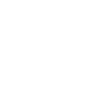

In [17]:
gdf.geometry.iloc[0]

In [18]:
import geopandas as gpd

# sensors_gdf already created earlier from sensor_map_table
# KML gdf = official tramas geometry

# Convert both to metric CRS for distance calculation
sensors_m = sensors_gdf.to_crs(epsg=25830)   # Spain / UTM zone 30N
tramas_m = gdf.to_crs(epsg=25830)

# give tramas an ID because original id/Name is empty
tramas_m = tramas_m.reset_index().rename(columns={"index": "TRAMA_ID"})

# nearest official traffic segment for each sensor
sensor_trama_match = gpd.sjoin_nearest(
    sensors_m,
    tramas_m[["TRAMA_ID", "geometry"]],
    how="left",
    distance_col="distance_to_trama_m"
)

sensor_trama_match = sensor_trama_match.drop(columns=["index_right"])

sensor_trama_match[
    ["SENSOR_ID", "LONGITUDE", "LATITUDE", "TRAMA_ID", "distance_to_trama_m"]
].head()

,SENSOR_ID,LONGITUDE,LATITUDE,TRAMA_ID,distance_to_trama_m
0,1001,-3.740786,40.409729,473,1.098377
1,1002,-3.743760,40.408030,62,2.923862
2,1003,-3.746834,40.406824,62,4.396518
3,1006,-3.736324,40.411894,457,10.227612
4,1009,-3.724909,40.416234,438,1.002857


In [19]:
sensor_trama_match["distance_to_trama_m"].describe()

count    4845.000000
mean       21.760602
std       192.974297
min         0.000135
25%         0.224863
50%         0.669417
75%         2.265238
max      3605.498217
Name: distance_to_trama_m, dtype: float64

In [20]:
sensor_trama_match.sort_values("distance_to_trama_m", ascending=False)[
    ["SENSOR_ID", "LONGITUDE", "LATITUDE", "TRAMA_ID", "distance_to_trama_m"]
].head(20)

,SENSOR_ID,LONGITUDE,LATITUDE,TRAMA_ID,distance_to_trama_m
4768,11431,-3.551635,40.408794,16,3605.498217
4770,11433,-3.551623,40.407359,16,3576.313692
4772,11435,-3.551633,40.405491,16,3546.566886
4747,11408,-3.552914,40.409472,16,3516.607831
4746,11407,-3.552523,40.405778,16,3475.264709
4767,11430,-3.553884,40.408749,16,3418.083483
4769,11432,-3.553817,40.407256,16,3390.962317
4771,11434,-3.553914,40.405465,16,3353.951567
4766,11429,-3.556363,40.404377,16,3134.923723
4745,11406,-3.557227,40.403800,16,3056.913225


In [21]:
sensor_trama_match["distance_group"] = pd.cut(
    sensor_trama_match["distance_to_trama_m"],
    bins=[0, 10, 50, 100, 500, 100000],
    labels=[
        "<10m",
        "10-50m",
        "50-100m",
        "100-500m",
        ">500m"
    ]
)

sensor_trama_match["distance_group"].value_counts()

distance_group
<10m        4208
10-50m       382
100-500m     123
50-100m      109
>500m         23
Name: count, dtype: int64

In [22]:
bad_spatial = sensor_trama_match[
    sensor_trama_match["distance_to_trama_m"] > 500
]

bad_spatial[
    ["SENSOR_ID","LONGITUDE","LATITUDE","distance_to_trama_m"]
].sort_values(
    "distance_to_trama_m",
    ascending=False
)

,SENSOR_ID,LONGITUDE,LATITUDE,distance_to_trama_m
4768,11431,-3.551635,40.408794,3605.498217
4770,11433,-3.551623,40.407359,3576.313692
4772,11435,-3.551633,40.405491,3546.566886
4747,11408,-3.552914,40.409472,3516.607831
4746,11407,-3.552523,40.405778,3475.264709
4767,11430,-3.553884,40.408749,3418.083483
4769,11432,-3.553817,40.407256,3390.962317
4771,11434,-3.553914,40.405465,3353.951567
4766,11429,-3.556363,40.404377,3134.923723
4745,11406,-3.557227,40.403800,3056.913225


In [23]:
#Get most extreme values
top_peaks = con.execute(f"""
SELECT
    SENSOR_ID,
    DATETIME,
    TRAFFIC_INTENSITY,
    OCCUPANCY,
    LOAD,
    AVERAGE_SPEED,
    ERROR_FLAG,
    INTEGRATION_PERIOD
FROM read_parquet('{imputed_path}')
WHERE TRAFFIC_INTENSITY IS NOT NULL
ORDER BY TRAFFIC_INTENSITY DESC
LIMIT 100
""").df()

top_peaks

,SENSOR_ID,DATETIME,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED,ERROR_FLAG,INTEGRATION_PERIOD
0,7023,2026-02-20 22:00:00,91368.333333,16.333333,100.0,0.0,N,7.00
1,7023,2026-02-17 13:00:00,91338.250000,17.000000,100.0,0.0,N,8.50
2,7023,2026-02-20 23:00:00,91269.250000,15.750000,100.0,0.0,N,4.00
3,7023,2026-02-17 03:00:00,91191.500000,16.000000,100.0,0.0,N,15.00
4,7023,2026-02-21 07:00:00,91068.000000,17.000000,100.0,0.0,N,3.00
...,...,...,...,...,...,...,...,...
95,5468,2023-01-20 07:00:00,85752.000000,18.500000,100.0,0.0,N,15.00
96,7023,2026-02-21 23:00:00,85711.000000,18.250000,100.0,0.0,N,5.25
97,7023,2026-02-17 22:00:00,85573.250000,18.500000,100.0,0.0,N,4.75
98,7023,2026-02-22 01:00:00,85518.250000,17.000000,100.0,0.0,N,15.00


In [24]:
print("Traffic:")
print(top_peaks["TRAFFIC_INTENSITY"].describe())

print("\nOccupancy:")
print(top_peaks["OCCUPANCY"].describe())

print("\nLoad:")
print(top_peaks["LOAD"].describe())

print("\nSpeed:")
print(top_peaks["AVERAGE_SPEED"].describe())

print("\nError flags:")
print(top_peaks["ERROR_FLAG"].value_counts(dropna=False))

print("\nIntegration period:")
print(top_peaks["INTEGRATION_PERIOD"].value_counts(dropna=False))

Traffic:
count      100.000000
mean     88739.119167
std       1681.722234
min      85484.000000
25%      87269.625000
50%      89232.250000
75%      90121.000000
max      91368.333333
Name: TRAFFIC_INTENSITY, dtype: float64

Occupancy:
count    100.000000
mean      17.844167
std        8.415468
min       14.000000
25%       15.937500
50%       17.250000
75%       18.000000
max      100.000000
Name: OCCUPANCY, dtype: float64

Load:
count    100.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: LOAD, dtype: float64

Speed:
count    100.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: AVERAGE_SPEED, dtype: float64

Error flags:
ERROR_FLAG
N    100
Name: count, dtype: int64

Integration period:
INTEGRATION_PERIOD
15.000000    34
8.500000      5
7.250000      5
6.000000      4
8.000000      4
4.000000      3
7.500000      3
9.000000      3
8.250000      3
7.750000 

In [25]:
sensor = 7023

con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY,
    OCCUPANCY,
    LOAD,
    AVERAGE_SPEED
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID = {sensor}
ORDER BY TRAFFIC_INTENSITY DESC
LIMIT 50
""").df()

,DATETIME,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED
0,2026-02-20 22:00:00,91368.333333,16.333333,100.0,0.0
1,2026-02-17 13:00:00,91338.250000,17.000000,100.0,0.0
2,2026-02-20 23:00:00,91269.250000,15.750000,100.0,0.0
3,2026-02-17 03:00:00,91191.500000,16.000000,100.0,0.0
4,2026-02-21 07:00:00,91068.000000,17.000000,100.0,0.0
5,2026-02-17 02:00:00,90986.250000,16.000000,100.0,0.0
6,2026-02-17 14:00:00,90900.250000,17.000000,100.0,0.0
7,2026-02-17 04:00:00,90847.750000,15.000000,100.0,0.0
8,2026-02-21 10:00:00,90835.500000,17.500000,100.0,0.0
9,2026-02-20 06:00:00,90712.000000,17.250000,100.0,0.0


In [26]:
con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS peaks
FROM (
    SELECT *
    FROM read_parquet('{imputed_path}')
    ORDER BY TRAFFIC_INTENSITY DESC
    LIMIT 1000
)
GROUP BY SENSOR_ID
ORDER BY peaks DESC
""").df()

,SENSOR_ID,peaks
0,7023,218
1,6070,131
2,10674,69
3,10298,62
4,4059,49
5,6069,47
6,5465,46
7,5670,40
8,6920,38
9,6940,32


In [27]:
sensors = (7023,6070,5465,10674,6642,6654,10265,6845)

con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,
    AVG(OCCUPANCY) AS avg_occ,
    AVG(LOAD) AS avg_load,
    AVG(AVERAGE_SPEED) AS avg_speed
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID IN {sensors}
GROUP BY SENSOR_ID
ORDER BY max_traffic DESC
""").df()

,SENSOR_ID,rows,avg_traffic,median_traffic,max_traffic,avg_occ,avg_load,avg_speed
0,7023,29845,748.061242,124.25,91368.333333,0.356351,2.415593,0.000000
1,5465,29928,495.802152,386.00,90910.000000,1.280728,13.724270,0.000000
2,10674,29928,233.022185,178.00,42949.666667,0.464544,2.611434,0.000000
3,6070,29928,387.193904,248.75,25120.750000,1.926441,10.311606,0.000000
4,6845,29928,3197.043421,3390.00,19614.000000,7.602454,0.752693,65.576162
5,6642,29928,2915.573680,2935.00,6793.500000,10.728089,47.188394,85.591979
6,6654,29928,2642.457292,2660.25,6004.000000,7.294068,47.144407,78.741569
7,10265,29928,2719.602827,2946.75,5884.250000,9.878777,48.477743,66.600936


In [28]:
con.execute(f"""
SELECT
    SENSOR_ID,
    ELEMENT_TYPE,
    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    AVG(OCCUPANCY) AS avg_occ,
    AVG(LOAD) AS avg_load,
    AVG(AVERAGE_SPEED) AS avg_speed
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID IN (
    7023,5465,6070,10674,
    6642,6654,10265,6845
)
GROUP BY SENSOR_ID, ELEMENT_TYPE
ORDER BY SENSOR_ID
""").df()

,SENSOR_ID,ELEMENT_TYPE,rows,avg_traffic,avg_occ,avg_load,avg_speed
0,5465,URB,29928,495.802152,1.280728,13.724270,0.000000
1,6070,URB,29928,387.193904,1.926441,10.311606,0.000000
2,6642,M30,29928,2915.573680,10.728089,47.188394,85.591979
3,6654,M30,29928,2642.457292,7.294068,47.144407,78.741569
4,6845,C30,29928,3197.043421,7.602454,0.752693,65.576162
5,7023,URB,29845,748.061242,0.356351,2.415593,0.000000
6,10265,M30,29928,2719.602827,9.878777,48.477743,66.600936
7,10674,URB,29928,233.022185,0.464544,2.611434,0.000000


In [29]:
con.execute(f"""
SELECT
    COUNT(*) AS rows,
    COUNT(CASE WHEN AVERAGE_SPEED > 0 THEN 1 END) AS speed_present,
    COUNT(CASE WHEN AVERAGE_SPEED = 0 THEN 1 END) AS speed_zero
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID = 7023
""").df()

,rows,speed_present,speed_zero
0,29845,0,27236


In [30]:
con.execute(f"""
SELECT
    COUNT(*) AS rows,
    COUNT(CASE WHEN AVERAGE_SPEED > 0 THEN 1 END) AS speed_present,
    COUNT(CASE WHEN AVERAGE_SPEED = 0 THEN 1 END) AS speed_zero
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID = 5465
""").df()

,rows,speed_present,speed_zero
0,29928,0,29866


In [31]:
con.execute(f"""
SELECT
    COUNT(*) AS rows,
    COUNT(CASE WHEN AVERAGE_SPEED > 0 THEN 1 END) AS speed_present,
    COUNT(CASE WHEN AVERAGE_SPEED = 0 THEN 1 END) AS speed_zero
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID = 6070
""").df()

,rows,speed_present,speed_zero
0,29928,0,29866


In [32]:
con.execute(f"""
SELECT
    COUNT(*) AS rows,
    COUNT(CASE WHEN AVERAGE_SPEED > 0 THEN 1 END) AS speed_present,
    COUNT(CASE WHEN AVERAGE_SPEED = 0 THEN 1 END) AS speed_zero
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID = 10674
""").df()

,rows,speed_present,speed_zero
0,29928,0,29866


In [33]:
con.execute(f"""
SELECT
    SENSOR_ID,

    MIN(OCCUPANCY) AS occ_min,
    AVG(OCCUPANCY) AS occ_avg,
    MAX(OCCUPANCY) AS occ_max,

    MIN(LOAD) AS load_min,
    AVG(LOAD) AS load_avg,
    MAX(LOAD) AS load_max

FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID IN (7023,5465,6070,10674)
GROUP BY SENSOR_ID
ORDER BY SENSOR_ID
""").df()

,SENSOR_ID,occ_min,occ_avg,occ_max,load_min,load_avg,load_max
0,5465,0.0,1.280728,94.75,0.0,13.724270,100.0
1,6070,0.0,1.926441,60.00,0.0,10.311606,100.0
2,7023,0.0,0.356351,100.00,0.0,2.415593,100.0
3,10674,0.0,0.464544,25.50,0.0,2.611434,100.0


In [34]:
con.execute(f"""
SELECT
    ELEMENT_TYPE,
    COUNT(*) AS rows,

    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,

    QUANTILE_CONT(TRAFFIC_INTENSITY,0.95) AS p95,
    QUANTILE_CONT(TRAFFIC_INTENSITY,0.99) AS p99,
    MAX(TRAFFIC_INTENSITY) AS max_traffic

FROM read_parquet('{imputed_path}')
GROUP BY ELEMENT_TYPE
ORDER BY max_traffic DESC
""").df()

,ELEMENT_TYPE,rows,avg_traffic,median_traffic,p95,p99,max_traffic
0,URB,127664838,268.348658,142.75,956.0,1678.25,91368.333333
1,C30,3678043,961.448929,480.00,3438.0,5034.00,19614.000000
2,M30,8634412,1273.656486,807.25,4058.5,5415.50,8215.250000


In [35]:
con.execute(f"""
SELECT
    COUNT(*) AS rows,

    COUNT(DISTINCT SENSOR_ID) AS sensors,

    MIN(TRAFFIC_INTENSITY) AS min_traffic,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,

    MIN(OCCUPANCY) AS min_occ,
    AVG(OCCUPANCY) AS avg_occ,
    MEDIAN(OCCUPANCY) AS median_occ,
    MAX(OCCUPANCY) AS max_occ,

    MIN(LOAD) AS min_load,
    AVG(LOAD) AS avg_load,
    MEDIAN(LOAD) AS median_load,
    MAX(LOAD) AS max_load,

    MIN(AVERAGE_SPEED) AS min_speed,
    AVG(AVERAGE_SPEED) AS avg_speed,
    MEDIAN(AVERAGE_SPEED) AS median_speed,
    MAX(AVERAGE_SPEED) AS max_speed

FROM read_parquet('{imputed_path}')
WHERE ELEMENT_TYPE='URB'
""").df()

,rows,sensors,min_traffic,avg_traffic,median_traffic,max_traffic,min_occ,avg_occ,median_occ,max_occ,min_load,avg_load,median_load,max_load,min_speed,avg_speed,median_speed,max_speed
0,127664838,4440,0.0,268.348658,142.75,91368.333333,0.0,5.279466,2.25,100.0,0.0,15.858198,11.0,100.0,0.0,0.0,0.0,0.0


In [36]:
con.execute(f"""
SELECT
    ELEMENT_TYPE,

    COUNT(DISTINCT SENSOR_ID) AS sensors,

    MIN(TRAFFIC_INTENSITY) AS min_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,

    MIN(OCCUPANCY) AS min_occ,
    MEDIAN(OCCUPANCY) AS median_occ,
    MAX(OCCUPANCY) AS max_occ,

    MIN(LOAD) AS min_load,
    MEDIAN(LOAD) AS median_load,
    MAX(LOAD) AS max_load,

    MIN(AVERAGE_SPEED) AS min_speed,
    MEDIAN(AVERAGE_SPEED) AS median_speed,
    MAX(AVERAGE_SPEED) AS max_speed

FROM read_parquet('{imputed_path}')
GROUP BY ELEMENT_TYPE
ORDER BY ELEMENT_TYPE
""").df()

,ELEMENT_TYPE,sensors,min_traffic,median_traffic,max_traffic,min_occ,median_occ,max_occ,min_load,median_load,max_load,min_speed,median_speed,max_speed
0,C30,147,0.0,480.00,19614.000000,0.0,2.913933,100.0,0.0,0.00,100.0,0.0,56.0,232.0
1,M30,304,0.0,807.25,8215.250000,0.0,3.750000,100.0,0.0,31.75,100.0,-127.0,72.0,246.0
2,URB,4440,0.0,142.75,91368.333333,0.0,2.250000,100.0,0.0,11.00,100.0,0.0,0.0,0.0


In [37]:
con.execute(f"""
SELECT
    SENSOR_ID,

    MAX(TRAFFIC_INTENSITY) AS max_traffic,

    AVG(OCCUPANCY) AS avg_occ,
    AVG(LOAD) AS avg_load,
    AVG(AVERAGE_SPEED) AS avg_speed

FROM read_parquet('{imputed_path}')
WHERE ELEMENT_TYPE='URB'
GROUP BY SENSOR_ID
ORDER BY max_traffic DESC
LIMIT 50
""").df()

,SENSOR_ID,max_traffic,avg_occ,avg_load,avg_speed
0,7023,91368.333333,0.356351,2.415593,0.0
1,5465,90910.000000,1.280728,13.724270,0.0
2,3947,90813.000000,8.146091,32.723436,0.0
3,5767,89515.500000,2.954487,11.398132,0.0
4,5468,89071.500000,6.053396,23.461463,0.0
5,6095,73800.000000,4.929163,20.816003,0.0
6,5470,66255.000000,4.034116,11.000541,0.0
7,5427,65960.000000,7.935999,31.208464,0.0
8,5824,58342.000000,9.137208,36.756587,0.0
9,10463,50965.000000,3.721145,25.230331,0.0


In [38]:
con.execute(f"""
SELECT
    ELEMENT_TYPE,

    COUNT(DISTINCT SENSOR_ID) AS sensors,
    COUNT(*) AS rows,

    MIN(TRAFFIC_INTENSITY) AS min_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,

    MIN(OCCUPANCY) AS min_occ,
    MEDIAN(OCCUPANCY) AS median_occ,
    AVG(OCCUPANCY) AS avg_occ,
    MAX(OCCUPANCY) AS max_occ,

    MIN(LOAD) AS min_load,
    MEDIAN(LOAD) AS median_load,
    AVG(LOAD) AS avg_load,
    MAX(LOAD) AS max_load,

    MIN(AVERAGE_SPEED) AS min_speed,
    MEDIAN(AVERAGE_SPEED) AS median_speed,
    AVG(AVERAGE_SPEED) AS avg_speed,
    MAX(AVERAGE_SPEED) AS max_speed

FROM read_parquet('{imputed_path}')
GROUP BY ELEMENT_TYPE
ORDER BY ELEMENT_TYPE
""").df()

,ELEMENT_TYPE,sensors,rows,min_traffic,median_traffic,avg_traffic,max_traffic,min_occ,median_occ,avg_occ,max_occ,min_load,median_load,avg_load,max_load,min_speed,median_speed,avg_speed,max_speed
0,C30,147,3678043,0.0,480.00,961.448929,19614.000000,0.0,2.913933,5.718261,100.0,0.0,0.00,0.517637,100.0,0.0,56.0,48.320858,232.0
1,M30,304,8634412,0.0,807.25,1273.656486,8215.250000,0.0,3.750000,5.611467,100.0,0.0,31.75,36.230368,100.0,-127.0,72.0,65.724942,246.0
2,URB,4440,127664838,0.0,142.75,268.348658,91368.333333,0.0,2.250000,5.279466,100.0,0.0,11.00,15.858198,100.0,0.0,0.0,0.000000,0.0


In [39]:
con.execute(f"""
SELECT
    ELEMENT_TYPE,

    COUNT(*) AS peaks_in_top_1000,

    MIN(TRAFFIC_INTENSITY) AS lowest_peak,
    MAX(TRAFFIC_INTENSITY) AS highest_peak

FROM (
    SELECT *
    FROM read_parquet('{imputed_path}')
    ORDER BY TRAFFIC_INTENSITY DESC
    LIMIT 1000
)
GROUP BY ELEMENT_TYPE
ORDER BY peaks_in_top_1000 DESC
""").df()

,ELEMENT_TYPE,peaks_in_top_1000,lowest_peak,highest_peak
0,URB,982,8795.5,91368.333333
1,C30,18,8815.5,19614.000000


In [40]:
con.execute(f"""
SELECT
    ELEMENT_TYPE,
    SENSOR_ID,
    TRAFFIC_INTENSITY,
    OCCUPANCY,
    LOAD,
    AVERAGE_SPEED
FROM read_parquet('{imputed_path}')
QUALIFY ROW_NUMBER() OVER(
    PARTITION BY ELEMENT_TYPE
    ORDER BY TRAFFIC_INTENSITY DESC
) <= 20
ORDER BY ELEMENT_TYPE, TRAFFIC_INTENSITY DESC
""").df()

,ELEMENT_TYPE,SENSOR_ID,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED
0,C30,6845,19614.000000,7.750000,0.00,63.25
1,C30,6878,18300.000000,45.000000,0.00,58.00
2,C30,6845,14766.000000,11.750000,0.00,63.75
3,C30,6878,14040.000000,100.000000,0.00,59.00
4,C30,6845,13878.000000,17.000000,0.00,64.00
5,C30,6878,13452.000000,95.500000,0.00,58.50
6,C30,6878,11961.000000,100.000000,0.00,59.50
7,C30,6878,11610.000000,61.000000,0.00,60.00
8,C30,6878,11610.000000,61.000000,0.00,60.00
9,C30,6878,11610.000000,61.000000,0.00,60.00


In [41]:
con.execute(f"""
SELECT
    COUNT(DISTINCT SENSOR_ID) AS urb_sensors
FROM read_parquet('{imputed_path}')
WHERE ELEMENT_TYPE = 'URB'
""").df()

,urb_sensors
0,4440


In [42]:
con.execute(f"""
SELECT
    ELEMENT_TYPE,
    COUNT(DISTINCT SENSOR_ID) AS sensors
FROM read_parquet('{imputed_path}')
GROUP BY ELEMENT_TYPE
ORDER BY sensors DESC
""").df()

,ELEMENT_TYPE,sensors
0,URB,4440
1,M30,304
2,C30,147


In [43]:
sensor_counts = con.execute(f"""
SELECT
    ELEMENT_TYPE,
    COUNT(DISTINCT SENSOR_ID) AS sensors
FROM read_parquet('{imputed_path}')
GROUP BY ELEMENT_TYPE
""").df()

sensor_counts["pct"] = (
    sensor_counts["sensors"] /
    sensor_counts["sensors"].sum() * 100
)

print(sensor_counts)

  ELEMENT_TYPE  sensors        pct
0          URB     4440  90.778982
1          C30      147   3.005520
2          M30      304   6.215498


In [44]:
con.execute(f"""
SELECT
    ELEMENT_TYPE,

    COUNT(DISTINCT SENSOR_ID) AS sensors,

    MAX(TRAFFIC_INTENSITY) AS max_traffic,

    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,

    AVG(OCCUPANCY) AS avg_occ,
    AVG(LOAD) AS avg_load,
    AVG(AVERAGE_SPEED) AS avg_speed

FROM read_parquet('{imputed_path}')
GROUP BY ELEMENT_TYPE
ORDER BY ELEMENT_TYPE
""").df()

,ELEMENT_TYPE,sensors,max_traffic,avg_traffic,median_traffic,avg_occ,avg_load,avg_speed
0,C30,147,19614.000000,961.448929,480.00,5.718261,0.517637,48.320858
1,M30,304,8215.250000,1273.656486,807.25,5.611467,36.230368,65.724942
2,URB,4440,91368.333333,268.348658,142.75,5.279466,15.858198,0.000000


In [45]:
con.execute(f"""
SELECT
    ELEMENT_TYPE,
    COUNT(*) AS peaks
FROM (
    SELECT *
    FROM read_parquet('{imputed_path}')
    ORDER BY TRAFFIC_INTENSITY DESC
    LIMIT 1000
)
GROUP BY ELEMENT_TYPE
""").df()

,ELEMENT_TYPE,peaks
0,C30,18
1,URB,982
